# Amazon Reviews Sentiment Analysis: Random Forest
**Name / IT Number:** Uthsara S.J.I. / `IT25100646`
**Model:** Random Forest Classifier

This notebook classifies Amazon reviews as positive or negative with a Random Forest on TF-IDF features. It uses the group's shared settings, the same 300,000-review random sample (seed 42), the same preprocessing, the same 80/20 stratified split, and 5-fold stratified cross-validation. All model varieties are compared with cross-validation on a development subset; the test set is used only once, for the final model.

## 1. Setup and configuration

In [1]:
%matplotlib inline
import os
import re
import random
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)


sns.set_theme(style="whitegrid")
STUDENT_ID = "IT25100646"

# settings
SEED = 42
SAMPLE_SIZE = 300000
DATA_PATH = "../data/raw/train.ft.txt"
OUT_DIR = Path("../results/outputs")
FIG_DIR = Path("../results/eda_visualizations")
METRICS_DIR = Path("../results/final_metrics")
for folder in (OUT_DIR, FIG_DIR, METRICS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# stop here if the dataset is missing
assert os.path.exists(DATA_PATH), "train.ft.txt not found in data/raw/"

## 2. Load and preprocess the data
The same steps are used in all six notebooks, so every model is trained and tested on exactly the same reviews:
1. a random sample of 300,000 reviews from `train.ft.txt` (seed 42; the file is sorted, so the first rows would give a biased sample)
2. removing missing values and duplicate reviews
3. text cleaning (lowercase; remove HTML tags, links, numbers and punctuation)
4. removing outliers in review length with the IQR method
5. an 80/20 stratified train/test split (random_state = 42)

Labels: **0 = Negative, 1 = Positive**.

In [2]:
# load a random sample of the reviews
with open(DATA_PATH, "r", encoding="utf-8") as f:
    total_lines = sum(1 for _ in f)

random.seed(SEED)
keep = set(random.sample(range(total_lines), SAMPLE_SIZE))

labels, texts = [], []
with open(DATA_PATH, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i in keep:
            tag, _, text = line.strip().partition(" ")
            labels.append(1 if tag == "__label__2" else 0)   # 1 = positive, 0 = negative
            texts.append(text)
df = pd.DataFrame({"label": labels, "text": texts})

# missing values and duplicates
df["text"] = df["text"].replace("", np.nan)
df = df.dropna(subset=["text"]).drop_duplicates(subset="text").reset_index(drop=True)

# text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)             # html tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # links
    text = re.sub(r"[^a-z\s]", " ", text)          # keep letters only
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].apply(clean_text)
df["word_count"] = df["clean_text"].str.split().str.len()

# outlier removal on review length (IQR method)
q1, q3 = df["word_count"].quantile([0.25, 0.75])
iqr = q3 - q1
df = df[(df["word_count"] >= q1 - 1.5 * iqr) &
        (df["word_count"] <= q3 + 1.5 * iqr)].reset_index(drop=True)

# 80/20 stratified train/test split
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 5-fold stratified cross-validation and a smaller subset of the training data for tuning
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def dev_subset(data, n=100000):
    subset, _ = train_test_split(data, train_size=n, stratify=data["label"], random_state=SEED)
    return subset.reset_index(drop=True)

print(f"full file: {total_lines:,} reviews | after preprocessing: {len(df):,}")
print(f"train: {len(train_df):,} | test: {len(test_df):,}")
print("positive share (train / test):", round(train_df["label"].mean(), 4), round(test_df["label"].mean(), 4))

full file: 3,600,000 reviews | after preprocessing: 299,983
train: 239,986 | test: 59,997
positive share (train / test): 0.5002 0.5002


In [3]:
def remove_stopwords(text):
    return " ".join(w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2)

for d in (train_df, test_df):
    d["processed_text"] = d["clean_text"].apply(remove_stopwords)

# Random Forests are slow on large sparse data, so varieties and tuning use a
# 50,000-review development subset; the final model uses the full training set.
dev = dev_subset(train_df, 50_000)
y_train, y_test, y_dev = train_df["label"], test_df["label"], dev["label"]
print("train:", len(train_df), "| test:", len(test_df), "| dev subset:", len(dev))
print(y_train.value_counts(normalize=True).round(4))

train: 239986 | test: 59997 | dev subset: 50000
label
1    0.5002
0    0.4998
Name: proportion, dtype: float64


## 3. Prepare features
Text is converted to TF-IDF features inside a `Pipeline`, so the vocabulary is learned only from the training folds. Random Forests are tree-based, so they **do not need feature scaling** and are robust to outliers; TF-IDF values are already on a 0-1 scale.

In [4]:
def rf_pipeline(max_features=20000, ngram=(1, 2), **rf_params):
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=max_features, ngram_range=ngram, sublinear_tf=True)),
        ("rf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **rf_params)),
    ])

def run_cv(name, pipe, text_col="clean_text"):
    start = time.time()
    s = cross_validate(pipe, dev[text_col], y_dev, cv=CV, scoring=["accuracy", "f1"],
                       return_train_score=True)
    row = {"variety": name,
           "train_f1": round(float(s["train_f1"].mean()), 4),
           "cv_accuracy": round(float(s["test_accuracy"].mean()), 4),
           "cv_f1": round(float(s["test_f1"].mean()), 4),
           "cv_std": round(float(s["test_f1"].std()), 4),
           "time_s": round(time.time() - start, 1)}
    print(f"{name}: CV F1 = {row['cv_f1']} (+/- {row['cv_std']})  [{row['time_s']} s]")
    return row

## 4. Baselines
A single Decision Tree and a default Random Forest (100 trees) on the same features, to show the benefit of ensembling.

In [5]:
results = []
dt_pipe = Pipeline([("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True)),
                    ("dt", DecisionTreeClassifier(random_state=SEED))])
results.append(run_cv("Decision Tree (baseline)", dt_pipe))
results.append(run_cv("RF default (100 trees)", rf_pipeline()))
pd.DataFrame(results)

Decision Tree (baseline): CV F1 = 0.7394 (+/- 0.0058)  [311.5 s]
RF default (100 trees): CV F1 = 0.8594 (+/- 0.0053)  [102.1 s]


,variety,train_f1,cv_accuracy,cv_f1,cv_std,time_s
0,Decision Tree (baseline),1.0,0.7392,0.7394,0.0058,311.5
1,RF default (100 trees),1.0,0.8619,0.8594,0.0053,102.1


## 5. Preprocessing variants
Stop words removed vs kept, unigrams only vs unigrams + bigrams, and class weighting.

In [6]:
results.append(run_cv("RF, stop words removed (processed_text)", rf_pipeline(), text_col="processed_text"))
results.append(run_cv("RF, unigrams only", rf_pipeline(ngram=(1, 1))))
results.append(run_cv("RF + class_weight=balanced", rf_pipeline(class_weight="balanced")))
variants_df = pd.DataFrame(results)
variants_df

RF, stop words removed (processed_text): CV F1 = 0.8534 (+/- 0.0039)  [69.3 s]
RF, unigrams only: CV F1 = 0.8488 (+/- 0.0045)  [60.1 s]
RF + class_weight=balanced: CV F1 = 0.8596 (+/- 0.0032)  [103.9 s]


,variety,train_f1,cv_accuracy,cv_f1,cv_std,time_s
0,Decision Tree (baseline),1.0,0.7392,0.7394,0.0058,311.5
1,RF default (100 trees),1.0,0.8619,0.8594,0.0053,102.1
2,"RF, stop words removed (processed_text)",1.0,0.8539,0.8534,0.0039,69.3
3,"RF, unigrams only",1.0,0.8526,0.8488,0.0045,60.1
4,RF + class_weight=balanced,1.0,0.8621,0.8596,0.0032,103.9


**Observations (sections 4-5)**

- A single Decision Tree reaches a CV F1 of 0.7394, while the default Random Forest (100 trees) reaches 0.8594, which is 12.0 points better. Both have a train F1 of 1.0, so a single tree memorises the training data; averaging many trees reduces this variance.
- Removing stop words lowered the F1 to 0.8534 (-0.60 points) and using unigrams only lowered it to 0.8488 (-1.06 points). This is the same pattern as in the other models.
- `class_weight="balanced"` made no real difference (0.8596 vs 0.8594), because the classes are already balanced (50.0 % / 50.0 %).

## 6. Manual hyperparameter exploration
One hyperparameter is varied at a time (others at default) to show the bias/variance trade-off. A 20,000-review subset is used here to keep the run time reasonable.

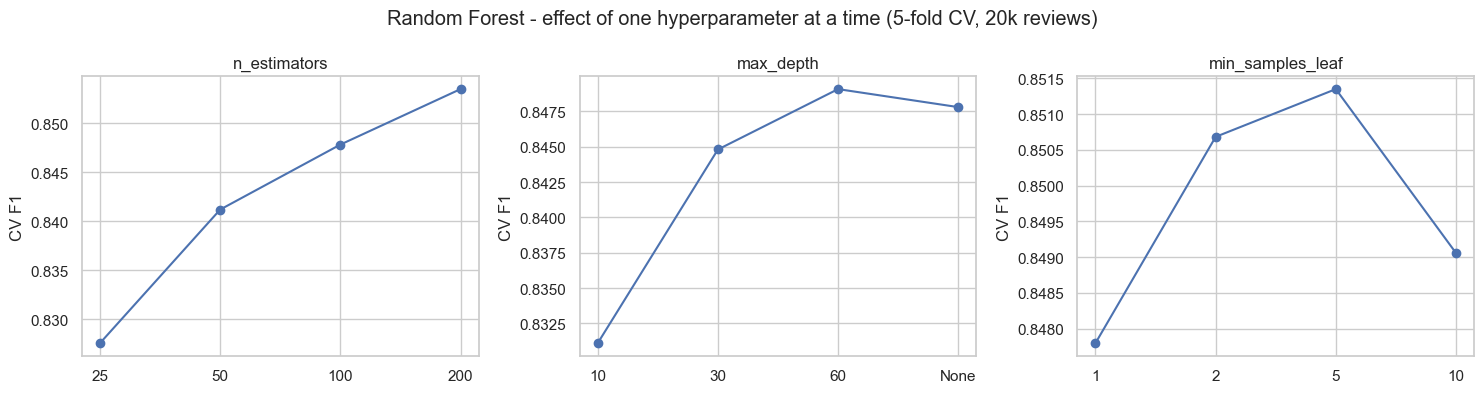

,parameter,value,cv_f1
0,n_estimators,25,0.8276
1,n_estimators,50,0.8412
2,n_estimators,100,0.8478
3,n_estimators,200,0.8535
4,max_depth,10,0.8311
5,max_depth,30,0.8448
6,max_depth,60,0.8491
7,max_depth,None,0.8478
8,min_samples_leaf,1,0.8478
9,min_samples_leaf,2,0.8507


In [7]:
explore = dev_subset(dev, 20_000)
explore_grid = {"n_estimators": [25, 50, 100, 200],
                "max_depth": [10, 30, 60, None],
                "min_samples_leaf": [1, 2, 5, 10]}
explore_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (param, vals) in zip(axes, explore_grid.items()):
    means = []
    for v in vals:
        s = cross_validate(rf_pipeline(**{param: v}), explore["clean_text"], explore["label"],
                           cv=CV, scoring="f1")
        means.append(s["test_score"].mean())
        explore_rows.append({"parameter": param, "value": str(v), "cv_f1": round(means[-1], 4)})
    ax.plot([str(v) for v in vals], means, marker="o")
    ax.set_title(param); ax.set_ylabel("CV F1")
plt.suptitle("Random Forest - effect of one hyperparameter at a time (5-fold CV, 20k reviews)")
plt.tight_layout()
plt.savefig(FIG_DIR / "rf_manual_exploration.png", dpi=150, bbox_inches="tight")
plt.show()
explore_df = pd.DataFrame(explore_rows)
explore_df

**Observations (section 6)**

- More trees always helped: the CV F1 rose from 0.8276 with 25 trees to 0.8535 with 200 trees, with smaller gains after 100 trees.
- Shallow trees under-fit: max_depth = 10 gives only 0.8311. A depth of 60 (0.8491) or no limit (0.8478) works best.
- min_samples_leaf of 2 to 5 is slightly better than 1 (0.8507 to 0.8513 vs 0.8478), and 10 is lower again (0.8491).

## 7. GridSearchCV (systematic tuning)
16 combinations × 5 folds = 80 fits on the 50,000-review development subset, scored by F1.

In [8]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True)),
    ("rf", RandomForestClassifier(random_state=SEED, n_jobs=1)),
])
param_grid = {
    "rf__n_estimators": [100, 200],
    "rf__max_depth": [None, 60],
    "rf__min_samples_leaf": [1, 2],
    "rf__max_features": ["sqrt", "log2"],
}
grid = GridSearchCV(pipe, param_grid, cv=CV, scoring="f1", n_jobs=-1,
                    verbose=1, return_train_score=True)
start = time.time()
grid.fit(dev["clean_text"], y_dev)
n_models = len(grid.cv_results_["params"])
print(f"time: {(time.time() - start) / 60:.1f} min")
print("Combinations tried:", n_models, "| total fits:", n_models * CV.get_n_splits())
print("Best params:", grid.best_params_, "| best CV F1:", round(grid.best_score_, 4))

cv_table = pd.DataFrame(grid.cv_results_)[[
    "param_rf__n_estimators", "param_rf__max_depth", "param_rf__min_samples_leaf",
    "param_rf__max_features", "mean_train_score", "mean_test_score", "std_test_score",
    "rank_test_score"]].sort_values("rank_test_score")
cv_table.round(4)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
time: 12.8 min
Combinations tried: 16 | total fits: 80
Best params: {'rf__max_depth': None, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 2, 'rf__n_estimators': 200} | best CV F1: 0.8742


,param_rf__n_estimators,param_rf__max_depth,param_rf__min_samples_leaf,param_rf__max_features,mean_train_score,mean_test_score,std_test_score,rank_test_score
7,200,None,2,log2,0.9650,0.8742,0.0031,1
5,200,None,1,log2,1.0000,0.8723,0.0030,2
6,100,None,2,log2,0.9622,0.8688,0.0025,3
1,200,None,1,sqrt,1.0000,0.8642,0.0048,4
3,200,None,2,sqrt,0.9928,0.8640,0.0040,5
4,100,None,1,log2,1.0000,0.8638,0.0036,6
9,200,60,1,sqrt,0.9906,0.8631,0.0045,7
11,200,60,2,sqrt,0.9713,0.8609,0.0048,8
2,100,None,2,sqrt,0.9918,0.8600,0.0048,9
0,100,None,1,sqrt,1.0000,0.8594,0.0053,10


**Observations (section 7)**

- The best setting is 200 trees, no depth limit, `max_features="log2"` and min_samples_leaf = 2, with a CV F1 of 0.8742 (std 0.0031).
- `log2` was better than `sqrt` (the best `sqrt` setting reached 0.8642). With 20,000 features, `log2` uses about 14 features per split and `sqrt` about 141, so the `log2` trees are more different from each other.
- 200 trees beat 100 trees in matching settings (for example 0.8742 vs 0.8688).
- The gap between the train score (0.9650) and the CV score (0.8742) shows that the forest still over-fits a little.

## 8. Final evaluation of the best model
The best configuration is trained on the full training set (239,986 reviews). The test set is used only here, once.

training time: 83.9 s
Accuracy : 0.8896
Precision: 0.8961
Recall   : 0.8814
F1 Score : 0.8887
ROC AUC  : 0.9571

              precision    recall  f1-score   support

    Negative     0.8833    0.8977    0.8904     29986
    Positive     0.8961    0.8814    0.8887     30011

    accuracy                         0.8896     59997
   macro avg     0.8897    0.8896    0.8896     59997
weighted avg     0.8897    0.8896    0.8896     59997

Confusion matrix:
 [[26919  3067]
 [ 3558 26453]]


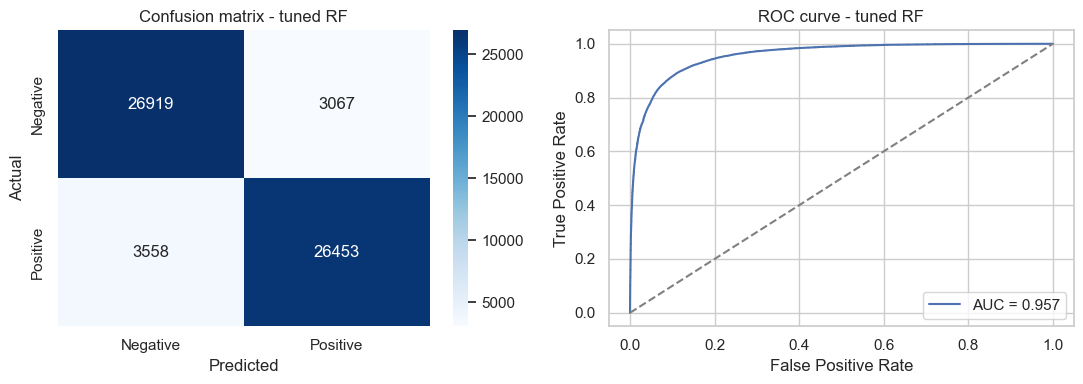

In [9]:
best_rf = clone(grid.best_estimator_)
best_rf.set_params(rf__n_jobs=-1)
start = time.time()
best_rf.fit(train_df["clean_text"], y_train)
rf_train_time = round(time.time() - start, 1)
print(f"training time: {rf_train_time} s")

pred = best_rf.predict(test_df["clean_text"])
prob = best_rf.predict_proba(test_df["clean_text"])[:, 1]
acc, prec = accuracy_score(y_test, pred), precision_score(y_test, pred)
rec, f1 = recall_score(y_test, pred), f1_score(y_test, pred)
auc = roc_auc_score(y_test, prob)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {auc:.4f}\n")
print(classification_report(y_test, pred, target_names=["Negative", "Positive"], digits=4))

cm = confusion_matrix(y_test, pred)
print("Confusion matrix:\n", cm)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion matrix - tuned RF")
fpr, tpr, _ = roc_curve(y_test, prob)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curve - tuned RF"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "rf_confusion_matrix_roc.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations (section 8)**

- On the test set the final model reaches accuracy 0.8896, precision 0.8961, recall 0.8814, F1 0.8887 and ROC-AUC 0.9571.
- There are 6,625 errors (11.04 %): 3,067 negative reviews predicted as positive and 3,558 positive reviews predicted as negative, so the model misses more positive reviews (recall 0.8814).
- The test F1 is 1.45 points above the CV F1 (0.8742), because the final model was trained on all 239,986 training reviews.
- The error rate increases with review length: 10.04 % short, 10.29 % medium and 12.83 % long.

## 9. Feature importance and error analysis

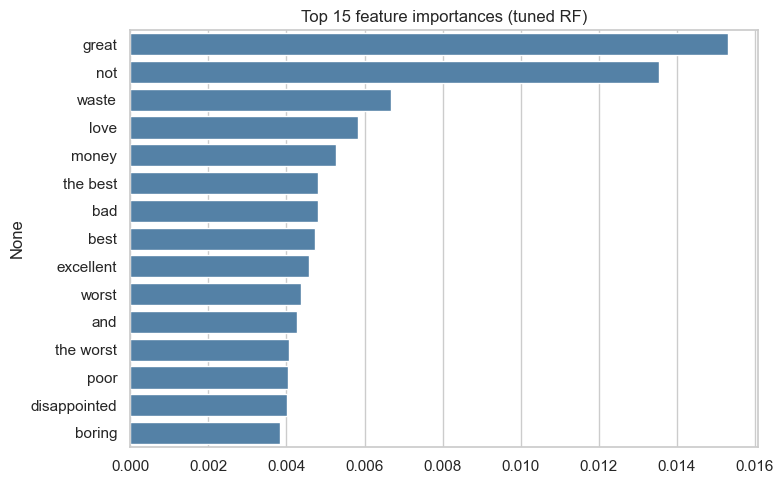

Total errors: 6625 of 59997

Error rate by review length:
                 mean   sum  count
length_bucket                     
short          0.1004  2026  20171
medium         0.1029  2062  20048
long           0.1283  2537  19778


In [10]:
names = np.array(best_rf.named_steps["tfidf"].get_feature_names_out())
imp = pd.Series(best_rf.named_steps["rf"].feature_importances_, index=names)
imp = imp.sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Top 15 feature importances (tuned RF)")
plt.tight_layout()
plt.savefig(FIG_DIR / "rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

err = pd.DataFrame({"true": y_test.values, "pred": pred, "prob": prob,
                    "word_count": test_df["word_count"].values, "text": test_df["text"].values})
err["wrong"] = err["true"] != err["pred"]
err["length_bucket"] = pd.qcut(err["word_count"], q=3, labels=["short", "medium", "long"])
print("Total errors:", err["wrong"].sum(), "of", len(err))
print("\nError rate by review length:")
print(err.groupby("length_bucket", observed=True)["wrong"].agg(["mean", "sum", "count"]).round(4))

## 10. Summary of results and saving

In [11]:
rows = [{"model_variant": r["variety"], "validation": "5-fold CV (50k dev subset)",
         "accuracy": r["cv_accuracy"], "f1": r["cv_f1"], "roc_auc": None}
        for _, r in variants_df.iterrows()]
rows.append({"model_variant": f"Tuned (GridSearchCV): {grid.best_params_}",
             "validation": "5-fold CV (50k dev subset)",
             "accuracy": None, "f1": round(grid.best_score_, 4), "roc_auc": None})
rows.append({"model_variant": "FINAL: tuned Random Forest on full training set",
             "validation": f"Held-out test set ({len(test_df):,} reviews)",
             "accuracy": round(acc, 4), "f1": round(f1, 4), "roc_auc": round(auc, 4)})
summary = pd.DataFrame(rows)
summary.to_csv(OUT_DIR / "rf_model_summary.csv", index=False)
cv_table.to_csv(OUT_DIR / "rf_gridsearch_results.csv", index=False)
explore_df.to_csv(OUT_DIR / "rf_manual_exploration.csv", index=False)
joblib.dump(best_rf, OUT_DIR / "rf_final_model.joblib", compress=3)
print("Saved:", OUT_DIR / "rf_model_summary.csv")

# save the final result for the group comparison (same format in all six notebooks)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
result = {
    "model": "Random Forest", "student_id": STUDENT_ID,
    "accuracy": round(accuracy_score(y_test, pred), 4),
    "precision": round(precision_score(y_test, pred), 4),
    "recall": round(recall_score(y_test, pred), 4),
    "f1": round(f1_score(y_test, pred), 4),
    "f1_macro": round(f1_score(y_test, pred, average="macro"), 4),
    "roc_auc": round(roc_auc_score(y_test, prob), 4),
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "cv_f1_mean": round(grid.best_score_, 4),
    "cv_f1_std": round(grid.cv_results_["std_test_score"][grid.best_index_], 4),
    "train_time_s": rf_train_time, "n_train": len(train_df),
    "best_params": str(grid.best_params_), "notes": "Tuned on 50k dev subset with 5-fold CV",
}
pd.DataFrame([result]).to_csv(os.path.join(METRICS_DIR, "Random_Forest.csv"), index=False)
print("Saved:", os.path.join(METRICS_DIR, "Random_Forest.csv"))

pd.set_option("display.max_colwidth", 90)
summary

Saved: ..\results\outputs\rf_model_summary.csv
Saved: ..\results\final_metrics\Random_Forest.csv


,model_variant,validation,accuracy,f1,roc_auc
0,Decision Tree (baseline),5-fold CV (50k dev subset),0.7392,0.7394,NaN
1,RF default (100 trees),5-fold CV (50k dev subset),0.8619,0.8594,NaN
2,"RF, stop words removed (processed_text)",5-fold CV (50k dev subset),0.8539,0.8534,NaN
3,"RF, unigrams only",5-fold CV (50k dev subset),0.8526,0.8488,NaN
4,RF + class_weight=balanced,5-fold CV (50k dev subset),0.8621,0.8596,NaN
5,"Tuned (GridSearchCV): {'rf__max_depth': None, 'rf__max_features': 'log2', 'rf__min_sam...",5-fold CV (50k dev subset),NaN,0.8742,NaN
6,FINAL: tuned Random Forest on full training set,"Held-out test set (59,997 reviews)",0.8896,0.8887,0.9571


## 11. Discussion

- **Suitability:** a Random Forest averages many different decision trees, which reduces the high variance of a single tree. It can learn non-linear word combinations, needs no feature scaling, and gives feature importance for interpretation.
- **Metrics:** accuracy, precision, recall, F1, ROC-AUC and the confusion matrix. The classes are balanced, so accuracy is meaningful; F1 and ROC-AUC show that neither class is favoured. Validation: stratified 5-fold CV on the development subset, and a final check on the shared test set (59,997 reviews).
- **Comparison:** Decision Tree (CV F1 0.7394) → default Random Forest (0.8594) → tuned Random Forest (0.8742). The tuned forest reached F1 0.8887 on the test set, so the tuned model with `log2` features is the best variety.
- **Limitations:** 200 full-depth trees make a large, slow model, and its F1 is 4.23 points below the Linear SVM (0.8887 vs 0.9310). TF-IDF features are sparse and high-dimensional, which suits linear models better than trees. Feature importance shows which words matter but not whether they are positive or negative.